This notebook tries to imporve the assignment of the tracked tones to different satellites

In [3]:
# import package & load peak array
from math import inf
from telnetlib import DO
from scipy import io as sio
from scipy.optimize import linear_sum_assignment
import numpy as np
import matplotlib.pyplot as plt

Step 1: convert the peak_array matrix to discrete point set $\{(t_i, f_i)\}$ 

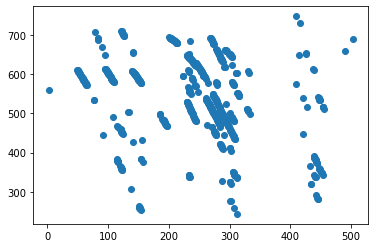

In [5]:
# convert the peak array to discrete point set {(t_i, f_i)}
# point_array : [# of points, 2]
# point_array[:, 1] = time 
# point_array[:, 2] = freq bin

##### choose one path #####
# peak_file_path = '/home/jidazhang/Desktop/starlink_ofdm/Central_Tone_Tracking/peak_arr_9_14_11_27_5.mat'
peak_file_path = "D:\\Desktop\study\\2023_summer\\starlink_ofdm\\Central_Tone_Tracking\\peak_arr_9_14_11_27_5.mat"
peak_array = sio.loadmat(peak_file_path)['peak_array']

is_empty = True
time = 1
step = 0.5
fbin_hardware = 517
for i in range(np.shape(peak_array)[0]):
    t_i = time+step * (i - 1)
    point_t_i = peak_array[i, :]
    none_zeros_freq_bin = [idx for idx, val in enumerate(point_t_i) if val != 0 and idx != fbin_hardware]
    if len(none_zeros_freq_bin) == 0:
        continue
    # add the freq_bin by 1 since index starts from 0 in Python
    for idx, val in enumerate(none_zeros_freq_bin):
        none_zeros_freq_bin[idx] += 1
    
    arr_t_i = np.vstack((t_i * np.ones(len(none_zeros_freq_bin)), none_zeros_freq_bin)).T
    if is_empty:
        point_array = arr_t_i
        is_empty = False
    else:
        point_array = np.concatenate((point_array, arr_t_i), axis=0)

# plot the discrete points
plt.scatter(point_array[:, 0], point_array[:, 1])
plt.show()

Step 2: merge adjacent points and assign them to one track

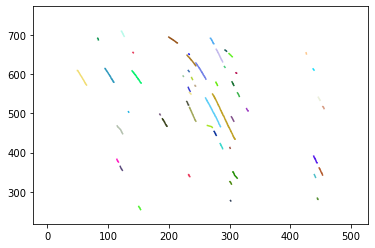

In [15]:
# assign the points to satellites
class DopplerTrack(object):
    num_tracks = 0
    def __init__(self, point) -> None:
        self.track_id = DopplerTrack.num_tracks
        DopplerTrack.num_tracks += 1
        self.track_points = np.array([point])
        self.slope = None
        self.intercept = None

    def update(self, point) -> None:
        # add peak to the track_points if there are elements in peak
        self.track_points = np.concatenate((self.track_points, np.array([point])), axis=0)
        self.slope, self.intercept = np.polyfit(self.track_points[:, 0], self.track_points[:, 1], 1)
        # self.linear_model.fit(np.array([self.track_points[:, 0]]), np.array([self.track_points[:, 1]]))
    
    def fit_err(self, point):
        if np.size(self.track_points, 0) < 6:
            return inf
        pred = self.slope * point[0] + self.intercept
        return np.abs(pred - point[1])


curr_tracks = []
all_tracks = []
for i in range(np.size(point_array, 0)):
    cur_point = point_array[i, :]

    if len(curr_tracks) == 0:
        # create new tracks for the first point
        trk = DopplerTrack(cur_point)
        curr_tracks.append(trk)
    else:
        # search the existing tracks which the new point might belong to
        if_assign_to_existing_track = False
        potential_trk = []
        for trk in curr_tracks:
            last_point_in_trk = trk.track_points[-1, :]
            last_point_t = last_point_in_trk[0]
            last_point_f = last_point_in_trk[1]
            # if the new point is close enough
            if (cur_point[1] <= last_point_f) and ((cur_point[0] <= last_point_t + 10 and cur_point[1] >= last_point_f - 5)):
                # trk.update(cur_point)
                if_assign_to_existing_track = True
                potential_trk.append(trk)
                # break
        if if_assign_to_existing_track:
            last_point_t = [val.track_points[-1, :][0] for idx, val in enumerate(potential_trk)]
            trk_most_probable = potential_trk[np.argmax(last_point_t)]
            trk_most_probable.update(cur_point)
        else:
            trk = DopplerTrack(cur_point)
            curr_tracks.append(trk)

track_dict = {}
for track in curr_tracks:
    track_dict["track_"+str(track.track_id)] = track.track_points
    # print(track.track_id, ":", track.track_points, "\n")

for track in curr_tracks:
    col = (np.random.random(), np.random.random(), np.random.random())
    # plt.scatter(track.track_points[:, 0], track.track_points[:, 1], marker='.', color=col)
    plt.plot(track.track_points[:, 0], track.track_points[:, 1], color=col)
plt.show()  

Step 3: Trying to merge discontinueous tracks (TODO)

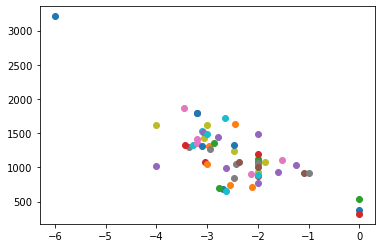

In [12]:
for track in curr_tracks:
    # print(track.slope, track.intercept)
    plt.scatter(track.slope, track.intercept)
plt.show()  

In [ ]:
output_tracks_file = "./output_tracks_2.mat"
sio.savemat(output_tracks_file, {'tracks_dict': track_dict})